# Audio Scam Detection — Training Notebook

This notebook trains a **scam-call vs normal-call audio classifier** using log-Mel spectrograms and a CNN.

## Dataset
Starter dataset repository: https://github.com/CyberSorceress/Scam-Call-Detection  
The repository describes a `Data/dataset.zip` containing `Scam Calls/` and `Normal Calls/` folders. Download and extract it yourself, check its license/provenance, then set `DATA_DIR` below.

**Important distinction:** scam-intent detection is not the same as AI-generated/synthetic voice detection. Links for ASVspoof anti-spoofing data are included at the end.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Install dependencies

In [ ]:
%pip -q install librosa soundfile scikit-learn matplotlib

## 2. Imports and configuration

In [5]:
import random, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa, librosa.display
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

# Google Colab example; change this to your extracted folder.
DATA_DIR = Path("/content/drive/MyDrive/Colab Notebooks/dataset")
# Windows example:
# DATA_DIR = Path(r"D:\datasets\Scam-Call-Detection\Data")

CLASS_DIRS = {
    "scam": ["Scam Calls", "scam", "Scam"],
    "normal": ["Normal Calls", "normal", "not_scam"]
}
AUDIO_EXTS = {".wav", ".mp3", ".flac", ".ogg", ".m4a", ".aac"}
SR, DURATION = 16000, 5
N_MELS, N_FFT, HOP = 64, 1024, 256
BATCH_SIZE, EPOCHS = 32, 20


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [7]:
import urllib.request
import zipfile
import os

# Define local path for downloading the dataset
zip_path = "/content/dataset.zip"
extract_path = "/content/dataset"

# Download dataset from the GitHub repository described in the notebook
url = "https://github.com/CyberSorceress/Scam-Call-Detection/raw/main/Data/dataset.zip"
print("Downloading dataset...")
urllib.request.urlretrieve(url, zip_path)

# Extract zip file
print("Extracting dataset...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# Update DATA_DIR in the configuration
DATA_DIR = Path(extract_path)
print(f"Dataset downloaded and extracted. DATA_DIR updated to: {DATA_DIR}")

Extracting dataset...
Dataset downloaded and extracted. DATA_DIR updated to: /content/dataset


## 3. Find dataset files and labels

In [10]:
from pathlib import Path
import os

base_search_path = Path("/content/dataset")

# List all directories to see the extracted layout
all_dirs = [str(p.relative_to(base_search_path)) for p in base_search_path.rglob("*") if p.is_dir()]
print("Available directories in extraction:", all_dirs)

# Let's dynamically find directories matching scam/normal context even if they differ slightly
def find_folder_robust(root, target_substrings):
    for p in root.rglob("*"):
        if p.is_dir():
            name_lower = p.name.lower()
            if any(sub in name_lower for sub in target_substrings):
                # Ensure it contains actual files
                files = [f for f in p.glob("*") if f.is_file()]
                if files:
                    return p
    return None

# Map keywords to detect classes
ROBUST_CLASS_DIRS = {
    "scam": ["scam", "fraud"],
    "normal": ["normal", "not_scam", "clean", "safe"]
}

folders = {k: find_folder_robust(base_search_path, v) for k, v in ROBUST_CLASS_DIRS.items()}
print("Robustly matched folders:", folders)

if any(v is None for v in folders.values()):
    # Fallback to manual folder selection from printed list if robust matching still fails
    raise FileNotFoundError("Could not automatically match class folders. Please inspect the list above and set CLASS_DIRS manually.")

def audio_files(folder):
    return sorted(p for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in AUDIO_EXTS)

rows = []
for label, folder in folders.items():
    files = audio_files(folder)
    print(label, "found files:", len(files))
    rows += [{"path": str(p), "label": label, "y": int(label == "scam")} for p in files]

df = pd.DataFrame(rows).drop_duplicates("path")
if df.empty:
    raise RuntimeError("No audio files found. Check folder structure and file extensions.")
display(df.head(), df["label"].value_counts().to_frame("count"))

Available directories in extraction: ['NORMAL_CALLS', 'SCAM_CALLS']
Robustly matched folders: {'scam': PosixPath('/content/dataset/SCAM_CALLS'), 'normal': PosixPath('/content/dataset/NORMAL_CALLS')}
scam found files: 3
normal found files: 14


,path,label,y
0,/content/dataset/SCAM_CALLS/scam_22.wav,scam,1
1,/content/dataset/SCAM_CALLS/scam_23_fraud.wav,scam,1
2,/content/dataset/SCAM_CALLS/scam_24.wav,scam,1
3,/content/dataset/NORMAL_CALLS/normal_10.mp3,normal,0
4,/content/dataset/NORMAL_CALLS/normal_11.mp3,normal,0


,count
label,
normal,14
scam,3


## 4. Split data

In [12]:
# Since the dataset is extremely small (3 scam, 14 normal), stratification during nested splits fails.
# We check if classes have enough members to safely stratify.
min_class_count = df.y.value_counts().min()

if min_class_count >= 4:
    train_df, tmp_df = train_test_split(df, test_size=0.30, random_state=SEED, stratify=df.y)
    val_df, test_df = train_test_split(tmp_df, test_size=0.50, random_state=SEED, stratify=tmp_df.y)
else:
    print("Dataset is too small for nested stratified splitting. Splitting without stratification...")
    train_df, tmp_df = train_test_split(df, test_size=0.30, random_state=SEED)
    val_df, test_df = train_test_split(tmp_df, test_size=0.50, random_state=SEED)

print("train / validation / test:", len(train_df), len(val_df), len(test_df))


Dataset is too small for nested stratified splitting. Splitting without stratification...
train / validation / test: 11 3 3


## 5. Audio preprocessing and log-Mel features

feature shape: (64, 313) sample label: scam


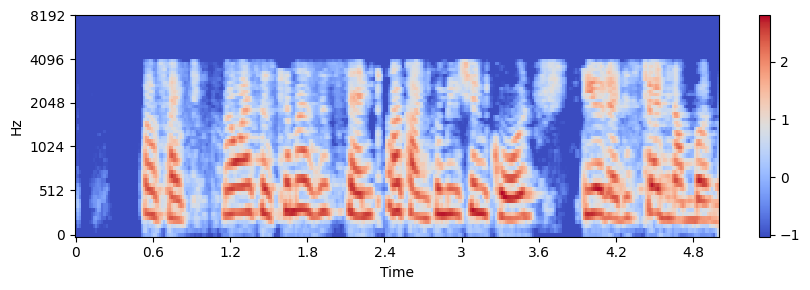

In [13]:
def load_audio(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    n = SR * DURATION
    if len(y) > n:
        start = (len(y) - n) // 2
        y = y[start:start+n]
    elif len(y) < n:
        y = np.pad(y, (0, n-len(y)))
    y = np.nan_to_num(y).astype(np.float32)
    peak = np.max(np.abs(y)) if len(y) else 0
    if peak > 1e-8: y /= peak
    return y

def logmel(path):
    y = load_audio(path)
    m = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=N_FFT,
                                        hop_length=HOP, n_mels=N_MELS, power=2)
    m = librosa.power_to_db(m, ref=np.max)
    return ((m - m.mean()) / (m.std() + 1e-6)).astype(np.float32)

ex = logmel(df.iloc[0].path)
print("feature shape:", ex.shape, "sample label:", df.iloc[0].label)
plt.figure(figsize=(9,3))
librosa.display.specshow(ex, sr=SR, hop_length=HOP, x_axis="time", y_axis="mel")
plt.colorbar(); plt.tight_layout(); plt.show()


## 6. Extract feature arrays

In [14]:
def build_arrays(frame):
    X, y, errors = [], [], []
    for r in frame.itertuples():
        try:
            X.append(logmel(r.path)); y.append(int(r.y))
        except Exception as e:
            errors.append((r.path, str(e)))
    if errors: print("Unreadable files skipped:", len(errors), errors[:3])
    return np.asarray(X, np.float32)[..., None], np.asarray(y, np.int32)

X_train, y_train = build_arrays(train_df)
X_val, y_val = build_arrays(val_df)
X_test, y_test = build_arrays(test_df)
print(X_train.shape, X_val.shape, X_test.shape)
if len(np.unique(y_train)) < 2: raise ValueError("Training data needs both classes.")


(11, 64, 313, 1) (3, 64, 313, 1) (3, 64, 313, 1)


## 7. Build and train CNN

In [15]:
inp = keras.Input(shape=X_train.shape[1:])
x = layers.Conv2D(32, 3, padding="same", use_bias=False)(inp)
x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
x = layers.MaxPooling2D(2)(x); x = layers.Dropout(0.15)(x)
x = layers.Conv2D(64, 3, padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
x = layers.MaxPooling2D(2)(x); x = layers.Dropout(0.20)(x)
x = layers.Conv2D(128, 3, padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
x = layers.GlobalAveragePooling2D()(x); x = layers.Dropout(0.30)(x)
x = layers.Dense(64, activation="relu")(x); x = layers.Dropout(0.25)(x)
out = layers.Dense(1, activation="sigmoid", name="scam_probability")(x)
model = keras.Model(inp, out, name="audio_scam_cnn")
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="binary_crossentropy",
              metrics=[keras.metrics.BinaryAccuracy(name="accuracy"),
                       keras.metrics.Precision(name="precision"),
                       keras.metrics.Recall(name="recall"),
                       keras.metrics.AUC(name="auc")])
model.summary()

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=5, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint("best_audio_scam_model.keras", monitor="val_auc", mode="max", save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)
]
class_weight = {0: len(y_train)/(2*max(1,(y_train==0).sum())),
                1: len(y_train)/(2*max(1,(y_train==1).sum()))}
history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=EPOCHS, batch_size=BATCH_SIZE,
                    callbacks=callbacks, class_weight=class_weight)


Model: "audio_scam_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 313, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 313, 32)    │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 313, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 313, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 156, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 156, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 156, 64)    │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 156, 64)    │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 156, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 78, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 78, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 78, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 78, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 78, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ scam_probability (Dense)        │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,665 (397.13 KB)

 Trainable params: 101,217 (395.38 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 17s 17s/step - accuracy: 0.8182 - auc: 0.4000 - loss: 0.7358 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 1.0000 - val_auc: 0.0000e+00 - val_loss: 0.6460 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step - accuracy: 0.7273 - auc: 0.4500 - loss: 0.8481 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 1.0000 - val_auc: 0.0000e+00 - val_loss: 0.6553 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 3/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.7273 - auc: 0.2000 - loss: 0.9058 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 1.0000 - val_auc: 0.0000e+00 - val_loss: 0.6711 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 4/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 0.9091 - auc: 1.0000 - loss: 0.5671 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_

## 8. Plot training history

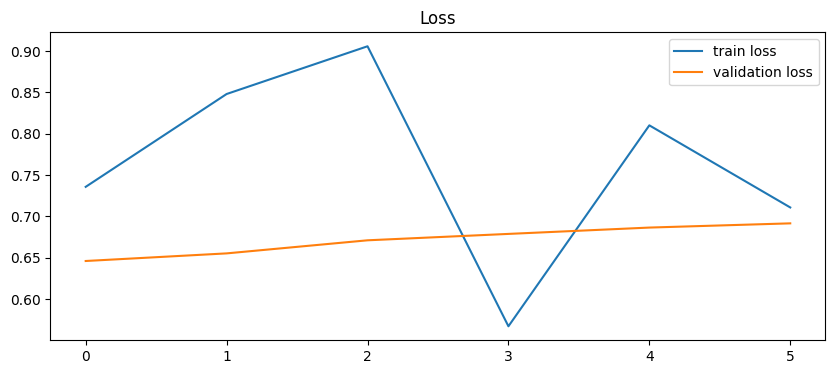

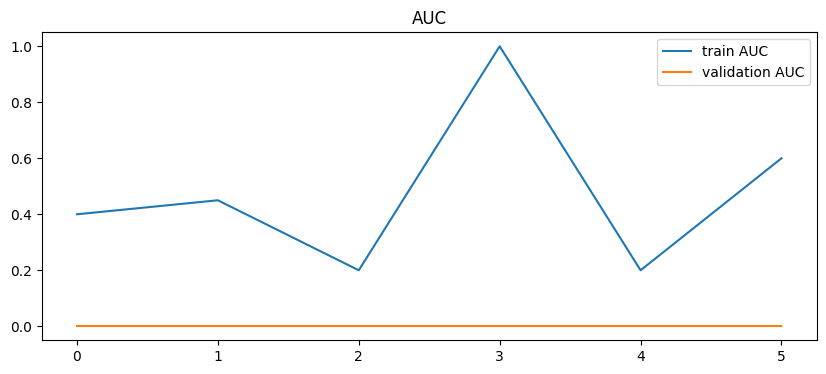

In [16]:
hist = pd.DataFrame(history.history)
plt.figure(figsize=(10,4))
plt.plot(hist.loss, label="train loss"); plt.plot(hist.val_loss, label="validation loss")
plt.legend(); plt.title("Loss"); plt.show()
plt.figure(figsize=(10,4))
plt.plot(hist.auc, label="train AUC"); plt.plot(hist.val_auc, label="validation AUC")
plt.legend(); plt.title("AUC"); plt.show()


## 9. Evaluate on held-out test set

In [17]:
probs = model.predict(X_test, batch_size=BATCH_SIZE).ravel()
threshold = 0.5  # Tune using validation data for the required false-positive/false-negative tradeoff.
preds = (probs >= threshold).astype(int)
print(classification_report(y_test, preds, target_names=["normal", "scam"], digits=4))
print("Confusion matrix:\n", confusion_matrix(y_test, preds))
if len(np.unique(y_test)) == 2:
    print("ROC-AUC:", round(roc_auc_score(y_test, probs), 4))


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 469ms/step
              precision    recall  f1-score   support

      normal     0.3333    1.0000    0.5000         1
        scam     0.0000    0.0000    0.0000         2

    accuracy                         0.3333         3
   macro avg     0.1667    0.5000    0.2500         3
weighted avg     0.1111    0.3333    0.1667         3

Confusion matrix:
 [[1 0]
 [2 0]]
ROC-AUC: 1.0


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


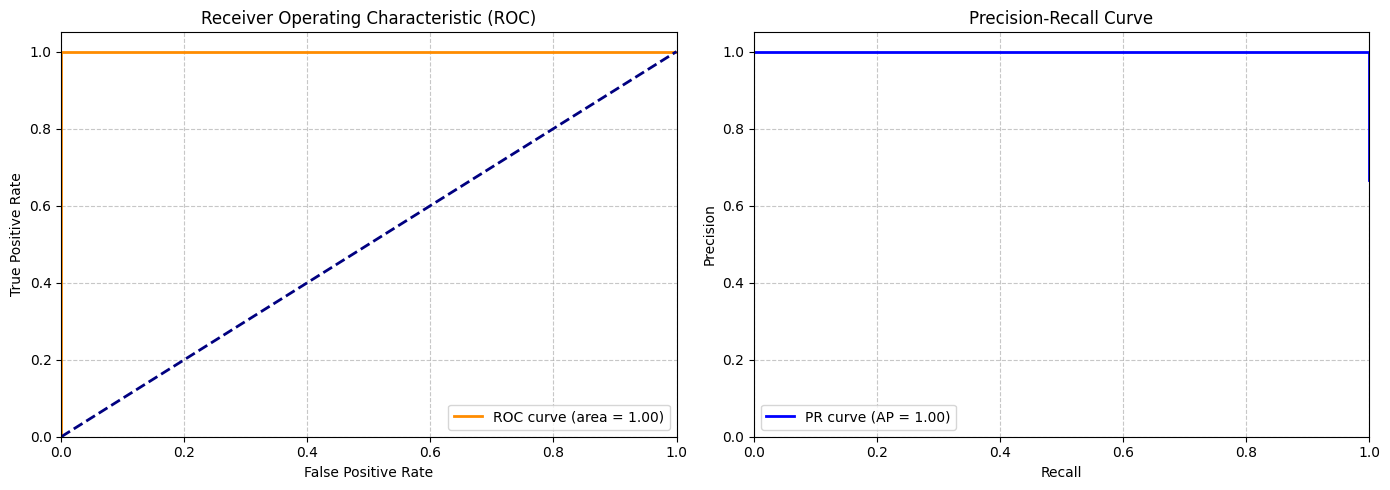

In [21]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Calculate metrics
fpr, tpr, _ = roc_curve(y_test, probs)
roc_auc = auc(fpr, tpr)

precision, recall, _ = precision_recall_curve(y_test, probs)
average_precision = average_precision_score(y_test, probs)

# Plot curves
plt.figure(figsize=(14, 5))

# ROC Curve
plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.7)

# Precision-Recall Curve
plt.subplot(1, 2, 2)
plt.plot(recall, precision, color='blue', lw=2, label=f'PR curve (AP = {average_precision:.2f})')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## 10. Save model and configuration

In [18]:
model.save("audio_scam_detection_model.keras")
config = {
    "task": "scam_vs_normal_call_audio",
    "sample_rate": SR, "duration_seconds": DURATION,
    "n_mels": N_MELS, "n_fft": N_FFT, "hop_length": HOP,
    "threshold": float(threshold),
    "labels": {"0": "normal", "1": "scam"},
    "feature": "per-example normalized log-Mel spectrogram"
}
with open("audio_scam_model_config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)
print("Saved audio_scam_detection_model.keras and audio_scam_model_config.json")


Saved audio_scam_detection_model.keras and audio_scam_model_config.json


In [20]:
import shutil
from pathlib import Path

# Define the destination directory in your Google Drive
drive_dest_dir = Path("/content/drive/MyDrive/Colab Notebooks/models")
drive_dest_dir.mkdir(parents=True, exist_ok=True)

# List of files to copy
files_to_save = [
    "audio_scam_detection_model.keras",
    "audio_scam_model_config.json"
]

for file_name in files_to_save:
    src_path = Path(file_name)
    if src_path.exists():
        dest_path = drive_dest_dir / file_name
        shutil.copy(src_path, dest_path)
        print(f"Successfully saved {file_name} to Google Drive at: {dest_path}")
    else:
        print(f"Error: {file_name} not found in current directory. Please make sure the training and save steps completed successfully.")

Successfully saved audio_scam_detection_model.keras to Google Drive at: /content/drive/MyDrive/Colab Notebooks/models/audio_scam_detection_model.keras
Successfully saved audio_scam_model_config.json to Google Drive at: /content/drive/MyDrive/Colab Notebooks/models/audio_scam_model_config.json


## 11. Predict one new file

In [19]:
def predict_audio_file(path, threshold=0.5):
    feat = logmel(path)[None, ..., None]
    score = float(model.predict(feat, verbose=0).ravel()[0])
    return {"label": "scam" if score >= threshold else "normal",
            "scam_score": score, "threshold": threshold}

# Example:
# predict_audio_file("/content/sample_call.wav")


## 12. Limitations and alternate dataset for deepfake voice detection

- This notebook detects **scam vs normal call audio**, not whether the voice is AI-generated.
- If audio clips from the same conversation/speaker/source are split across train and test, results can be inflated. Prefer group-aware splits when metadata permits.
- Scripted or synthetic data may not generalize to real calls, other languages, accents, codecs or background noise.
- Treat the score as one signal in your multimodal system, not proof of criminal activity.
- For **synthetic/deepfake voice detection**, use ASVspoof:
  - ASVspoof 2019: https://www.asvspoof.org/index2019.html
  - ASVspoof 2021: https://www.asvspoof.org/index2021.html
  - ASVspoof 2021 baseline systems and evaluation tools: https://github.com/asvspoof-challenge/2021
- ASVspoof uses protocol/metadata labels and access instructions. Follow the official protocol; do not guess labels from filenames.
